# Filtered aperture E/B shear maps on HEALPix (DP2, tract 9813)

Alex Broughton · April 2026. Rubin stack and Butler access required.

## Introduction

This notebook builds Schirmer-filtered aperture E- and B-mode shear maps on HEALPix for DP2
tract 9813, using HSM regauss shapes from the object table. These are weighted aperture
statistics, not a Kaiser-Squires reconstruction.

- E-mode: tangential shear gt weighted by the Schirmer filter Q.
- B-mode: cross shear g× weighted by the same Q; consistent with zero for pure lensing.
- Geometry: every HEALPix RING cell containing at least one source in the target tract is evaluated
  at its center. The KD-tree includes galaxies from neighboring tracts so the filter is complete at
  the tract edge; missing neighbors are skipped.
- Weights: inverse variance built from the per-object shape dispersion and measurement error.

Outline:

1. Setup: imports, configuration, Butler client, filter and aperture functions.
2. Load data: target-tract object table (needed columns only) and neighbor-tract ids.
3. Source selection: the selection_cuts.md cuts, plus a color-color red-sequence veto, a map of
   selected galaxies per HEALPix cell, then a filter-scale buffer from neighboring tracts.
4. Map on HEALPix: calibrate shears, then run the aperture statistic on every cell in the tract.
5. Peaks: local maxima of the E-mode map above a signal-to-noise threshold.
6. Figures: sky maps of E/B aperture mass, signal-to-noise, counts, and peaks.

## 1.0 Setup

### 1.1 Imports and configuration

All tunable quantities live in the CONFIG dictionary. Derived angular scales are computed
once from RS_INPUT_PIX so that changing the pixel scale propagates everywhere.

In [1]:
import gc
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import astropy.units as u
from astropy.table import Table, vstack
from scipy.spatial import cKDTree
from tqdm.auto import tqdm

from lsst.daf.butler import Butler
from lsst.sphgeom import Angle as SphAngle, Circle

%matplotlib inline
plt.rcParams.update({"font.size": 12})


# Repo layout: _data/ holds external inputs, output/ holds generated tables/catalogs, plots/ holds figures.
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = ROOT / "_data"
OUTPUT_DIR = ROOT / "output"
PLOTS_DIR = ROOT / "plots"
for _d in (OUTPUT_DIR, PLOTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)


def save_plot(fig, name):
    fig.savefig(PLOTS_DIR / f"{name}.pdf", bbox_inches="tight")


def tract_area_deg2(skymap, tract):
    """Area of a tract's unique (inner) region in deg^2."""
    region = skymap[tract].inner_sky_region
    if hasattr(region, "getArea"):  # sphgeom.Box, as in rings skymaps
        sr = region.getArea()
    else:  # convex polygon: sum the solid angles of a triangle fan
        v = np.array([[p.x(), p.y(), p.z()] for p in region.getVertices()])
        a = v[0]
        sr = sum(
            2 * np.arctan2(abs(a @ np.cross(b, c)), 1 + a @ b + b @ c + c @ a)
            for b, c in zip(v[1:-1], v[2:])
        )
    return float(sr * (180.0 / np.pi) ** 2)


In [2]:
CONFIG = {
    "REPO": "/sdf/data/rubin/repo/dp2_prep",  # Butler repository root
    "COLLECTION": "LSSTCam/runs/DRP/DP2/v30_0_0/DM-53881/stage3",  # Input collection
    "SKYMAP": "lsst_cells_v2",  # Skymap name for Butler
    "INSTRUMENT": "LSSTCam",  # Instrument dimension
    "TRACT": 9813,  # COSMOS
    # "TRACT": 8006, # Massive cluster
    "RS_INPUT_PIX": 3000,  # Schirmer scale in native catalog pixels
    "PIX_SCALE_ARCSEC": 0.2,  # Arcsec per pixel (converts RS_INPUT_PIX to sky angle)
    "SEARCH_RADIUS_RS_MULT": 3,  # this × Rs (in arcmin)
    "NSIDE": int(2**12),  # HEALPix NSIDE (RING); use a power of 2
    "PEAK_SN_MIN": 3.0,  # Peak S/N cut; use None to disable
    # Source selection, following selection_cuts.md (see section 3).
    "SNR_MIN": 5.0,  # Minimum per-band griz Sersic flux S/N
    "RESO_FACTOR_MIN": 0.125,  # Minimum PSF-resolution factor (star-galaxy separation)
    "COLOR_ABS_MAX": 5.0,  # Maximum |g-r|, |r-i|, |i-z| in AB magnitudes
    "EXTENDEDNESS_MIN": 0.2,  # Minimum griz model extendedness
    "E_SQ_MAX": 4.0,  # Maximum e1^2 + e2^2 for the HSM regauss distortion
    "T_MAX_ARCSEC2": None,  # Optional size cut on i_ixx + i_iyy; None disables it
    "RED_SEQ_SLOPE": 2.276,  # Red-sequence line: g-i = slope * (r-z) + intercept
    "RED_SEQ_INTERCEPT": -0.20,  # Objects above that line are rejected
}

# Filter scale Rs expressed in the angular units needed downstream.
CONFIG["RS_ARCSEC"] = float(CONFIG["RS_INPUT_PIX"]) * float(CONFIG["PIX_SCALE_ARCSEC"])
CONFIG["RS_ARCMIN"] = CONFIG["RS_ARCSEC"] / 60.0
CONFIG["RS_DEG"] = CONFIG["RS_ARCSEC"] / 3600.0

# Aperture radius used for the neighbor search around each HEALPix cell center.
CONFIG["THETA_MAX_ARCMIN"] = float(CONFIG["SEARCH_RADIUS_RS_MULT"]) * CONFIG["RS_ARCMIN"]
CONFIG["NSIDE"] = int(CONFIG["NSIDE"])

# Mean HEALPix pixel spacing, i.e. sqrt(pixel area), as a sanity check against Rs.
_mean_arcsec = float(np.rad2deg((4.0 * np.pi / 12.0) ** 0.5 / CONFIG["NSIDE"]) * 3600.0)
_npix = hp.nside2npix(CONFIG["NSIDE"])

print("TRACT =", CONFIG["TRACT"])
print(
    "Schirmer Rs =",
    CONFIG["RS_INPUT_PIX"],
    "pix @",
    CONFIG["PIX_SCALE_ARCSEC"],
    "arcsec/pix →",
    f"{CONFIG['RS_ARCMIN']:.3f} arcmin",
)
print(
    "search radius THETA_MAX_ARCMIN =",
    f"{CONFIG['THETA_MAX_ARCMIN']:.3f}",
    f"({CONFIG['SEARCH_RADIUS_RS_MULT']}×Rs) | NSIDE =",
    CONFIG["NSIDE"],
    f"(npix={_npix}; ~mean spacing {_mean_arcsec:.1f} arcsec)",
)

TRACT = 9813
Schirmer Rs = 3000 pix @ 0.2 arcsec/pix → 10.000 arcmin
search radius THETA_MAX_ARCMIN = 30.000 (3×Rs) | NSIDE = 4096 (npix=201326592; ~mean spacing 51.5 arcsec)


In [3]:
# Butler client for the repo/collection defined above.
butler = Butler(
    CONFIG["REPO"],
    collections=[CONFIG["COLLECTION"]],
    skymap=CONFIG["SKYMAP"],
    instrument=CONFIG["INSTRUMENT"],
)

### 1.2 Table helpers

Column access, magnitude conversion, the object-table column list, source selection, and the
tract-buffer helpers used when loading neighboring tracts.

In [4]:
def _col(tbl, name):
    """Column as a float64 numpy array."""
    return np.array(tbl[name]).astype(np.float64, copy=False)


def flux_to_abmag(flux_njy):
    """Convert nJy fluxes to AB magnitudes; non-positive or non-finite fluxes become NaN."""
    flux = np.asarray(flux_njy, dtype=np.float64)
    mag = np.full(flux.shape, np.nan, dtype=np.float64)
    good = np.isfinite(flux) & (flux > 0.0)
    mag[good] = (flux[good] * u.nJy).to(u.ABmag).value
    return mag


FLAG_COLUMNS = [
    "i_i_flag",
    "i_iPSF_flag",
    "i_hsmShapeRegauss_flag",
    "i_gaapFlux_flag",
    "sersic_no_data_flag",
    "sersic_unknown_flag",
    "shape_flag",
    "i_pixelFlags_bad",
    "i_pixelFlags_nodata",
    "i_pixelFlags_edge",
    "i_pixelFlags_saturatedCenter",
    "i_pixelFlags_crCenter",
    "i_pixelFlags_interpolatedCenter",
    "i_pixelFlags_suspectCenter",
]

OBJECT_COLUMNS = [
    "objectId",
    "coord_ra",
    "coord_dec",
    "detect_isDeblendedModelSource",
    "griz_model_extendedness",
    "i_hsmShapeRegauss_e1",
    "i_hsmShapeRegauss_e2",
    "i_hsmShapeRegauss_sigma",
    "i_ixx",
    "i_iyy",
    "i_ixxPSF",
    "i_iyyPSF",
    "i_inputCount",
    "g_sersicFlux",
    "g_sersicFluxErr",
    "r_sersicFlux",
    "r_sersicFluxErr",
    "i_sersicFlux",
    "i_sersicFluxErr",
    "z_sersicFlux",
    "z_sersicFluxErr",
] + FLAG_COLUMNS

SHEAR_COLUMNS = [
    "objectId",
    "coord_ra",
    "coord_dec",
    "i_hsmShapeRegauss_e1",
    "i_hsmShapeRegauss_e2",
    "i_hsmShapeRegauss_sigma",
]


def selection_mask(data):
    """Combined selection mask and the per-group masks that build it."""
    n = len(data)
    flag_columns = [c for c in FLAG_COLUMNS if c in data.colnames]

    flags_ok = np.ones(n, dtype=bool)
    for name in flag_columns:
        flags_ok &= ~np.asarray(data[name], dtype=bool)
    if "i_inputCount" in data.colnames:
        flags_ok &= np.asarray(data["i_inputCount"]) > 0

    primary_ok = np.asarray(data["detect_isDeblendedModelSource"], dtype=bool)

    e_sq = _col(data, "i_hsmShapeRegauss_e1") ** 2 + _col(data, "i_hsmShapeRegauss_e2") ** 2
    shape_ok = e_sq <= CONFIG["E_SQ_MAX"]

    t_obj = _col(data, "i_ixx") + _col(data, "i_iyy")
    with np.errstate(divide="ignore", invalid="ignore"):
        reso = 1.0 - (_col(data, "i_ixxPSF") + _col(data, "i_iyyPSF")) / t_obj
    reso_ok = reso > CONFIG["RESO_FACTOR_MIN"]

    mag = {b: flux_to_abmag(_col(data, f"{b}_sersicFlux")) for b in "griz"}
    with np.errstate(divide="ignore", invalid="ignore"):
        snr = {b: _col(data, f"{b}_sersicFlux") / _col(data, f"{b}_sersicFluxErr") for b in "griz"}

    snr_min = CONFIG["SNR_MIN"]
    detect_ok = _col(data, "griz_model_extendedness") > CONFIG["EXTENDEDNESS_MIN"]
    for b in "griz":
        detect_ok &= snr[b] > snr_min

    color_max = CONFIG["COLOR_ABS_MAX"]
    gi = mag["g"] - mag["i"]
    rz = mag["r"] - mag["z"]
    color_ok = np.abs(mag["g"] - mag["r"]) < color_max
    color_ok &= np.abs(mag["r"] - mag["i"]) < color_max
    color_ok &= np.abs(mag["i"] - mag["z"]) < color_max
    color_ok &= np.isfinite(gi) & np.isfinite(rz)
    color_ok &= ~(gi > CONFIG["RED_SEQ_SLOPE"] * rz + CONFIG["RED_SEQ_INTERCEPT"])

    size_ok = np.ones(n, dtype=bool)
    if CONFIG["T_MAX_ARCSEC2"] is not None:
        size_ok = t_obj < CONFIG["T_MAX_ARCSEC2"] / CONFIG["PIX_SCALE_ARCSEC"] ** 2

    groups = {
        "measurement + pixel flags": flags_ok,
        "deblended model source": primary_ok,
        "|e| <= 2": shape_ok,
        f"reso_factor > {CONFIG['RESO_FACTOR_MIN']}": reso_ok,
        f"extendedness + S/N > {snr_min:g}": detect_ok,
        "colors + red sequence": color_ok,
        "size": size_ok,
    }
    mask = np.ones(n, dtype=bool)
    for cut in groups.values():
        mask &= cut
    return mask, groups


def resolve_object_columns(butler, tract):
    """Intersect OBJECT_COLUMNS with the table schema without loading the rows."""
    data_id = {"tract": int(tract), "skymap": CONFIG["SKYMAP"]}
    try:
        names = set(
            butler.get("object", dataId=data_id, storageClass="ArrowSchema").names
        )
    except Exception as exc:
        print("ArrowSchema unavailable, requesting OBJECT_COLUMNS directly:", exc)
        return list(OBJECT_COLUMNS)
    cols = [c for c in OBJECT_COLUMNS if c in names]
    missing = [c for c in OBJECT_COLUMNS if c not in names]
    print("Missing columns:", missing or "none")
    print(f"Reading {len(cols)} of {len(names)} columns")
    return cols


def load_object_table(butler, tract, columns):
    """Object table for one tract, restricted to `columns`."""
    return butler.get(
        "object",
        dataId={"tract": int(tract), "skymap": CONFIG["SKYMAP"]},
        parameters={"columns": columns},
    )


def object_tract_ids(butler):
    """Tract ids that have an object table in the configured collection."""
    data_ids = butler.registry.queryDataIds(
        ["tract"],
        datasets="object",
        collections=CONFIG["COLLECTION"],
        skymap=CONFIG["SKYMAP"],
    )
    return {int(d["tract"]) for d in data_ids}


def buffered_tract_circle(tract_info, theta_max_deg):
    """Bounding circle of the tract outer polygon, expanded by theta_max_deg."""
    bc = tract_info.getOuterSkyPolygon().getBoundingCircle()
    return Circle(
        bc.getCenter(),
        SphAngle(bc.getOpeningAngle().asRadians() + np.deg2rad(theta_max_deg)),
    )


def neighbor_tract_ids(skymap, tract_id, available, theta_max_deg):
    """Available object-table tracts whose outer polygon meets the buffered target tract."""
    buf = buffered_tract_circle(skymap[int(tract_id)], theta_max_deg)
    neighbors = []
    for tid in sorted(available):
        if tid == tract_id:
            continue
        try:
            other = skymap[int(tid)].getOuterSkyPolygon()
            if buf.intersects(other):
                neighbors.append(int(tid))
        except Exception:
            continue
    return neighbors, buf


def in_circle(ra_deg, dec_deg, circle):
    """True for points inside a sphgeom Circle."""
    ra = np.deg2rad(np.asarray(ra_deg, dtype=np.float64))
    dec = np.deg2rad(np.asarray(dec_deg, dtype=np.float64))
    cosd = np.cos(dec)
    c = circle.getCenter()
    try:
        cx, cy, cz = float(c.x()), float(c.y()), float(c.z())
    except TypeError:
        cx, cy, cz = float(c.x), float(c.y), float(c.z)
    cosang = cosd * np.cos(ra) * cx + cosd * np.sin(ra) * cy + np.sin(dec) * cz
    return cosang >= np.cos(circle.getOpeningAngle().asRadians())


def shear_subset(tbl):
    """Keep only columns needed after selection."""
    cols = [c for c in SHEAR_COLUMNS if c in tbl.colnames]
    return tbl[cols]


def dedupe_objectid(tbl, n_target):
    """Drop duplicate objectId rows, keeping the target-tract copy when both exist."""
    if "objectId" not in tbl.colnames:
        from_target = np.arange(len(tbl)) < n_target
        return tbl, from_target
    ids = np.asarray(tbl["objectId"])
    _, first = np.unique(ids, return_index=True)
    first.sort()
    return tbl[first], first < n_target

### 1.3 Filter and aperture functions

Four helpers: the Schirmer filter profile, the tangential/cross shear rotation, the aperture
statistic evaluated at one sky position, and a peak finder on the HEALPix neighbor graph. The
next cell plots Q(r/Rs) with Rs and the search radius marked.

In [5]:
def schirmer_weight(r, rs):
    """Schirmer filter Q(r/Rs); r and rs in the same angular units (degrees here)."""
    r = np.asarray(r, dtype=np.float64)
    rs = float(rs)
    x = r / rs

    # Schirmer (2007) coefficients: a smooth band-pass in x with a tanh core.
    a, b, c, d, xc = 6.0, 150.0, 47.0, 50.0, 0.15

    # Outer envelope: rises near x ~ a/b and falls near x ~ c/d.
    q = 1.0 / (1.0 + np.exp(a - b * x) + np.exp(d * x - c))

    # Core term tanh(x/xc)/(x/xc), which tends to 1 as x -> 0.
    ratio = x / xc
    with np.errstate(divide="ignore", invalid="ignore"):
        inner = np.tanh(ratio) / ratio
    inner = np.where(np.abs(ratio) < 1e-14, 1.0, inner)

    q = q * inner
    q = np.where(np.isfinite(q), q, 0.0)  # Guard against 0/0 at the center
    return q


def gamma_tx_sky(ra, dec, g1, g2, center):
    """Tangential g_t and cross g_x shear about center (degrees, small-angle plane)."""
    ra = np.asarray(ra, dtype=np.float64)
    dec = np.asarray(dec, dtype=np.float64)
    g1 = np.asarray(g1, dtype=np.float64)
    g2 = np.asarray(g2, dtype=np.float64)
    ra0, dec0 = center

    # Local tangent plane about the center; RA offsets shrink by cos(dec).
    cos_dec0 = np.cos(np.deg2rad(dec0))
    dx = (ra - ra0) * cos_dec0
    dy = dec - dec0

    # Rotate the (g1, g2) spin-2 field into the frame of the center.
    phi = np.arctan2(dy, dx)
    c2 = np.cos(2.0 * phi)
    s2 = np.sin(2.0 * phi)
    gt = -(g1 * c2 + g2 * s2)
    gx = -g1 * s2 + g2 * c2
    return gt, gx

Schirmer (2007) filter Q(r/Rs) used to weight gt and g×. The inner taper is set by xc=0.15; the outer envelope falls near x∼c/d=0.94. The search disc is SEARCH_RADIUS_RS_MULT times Rs.

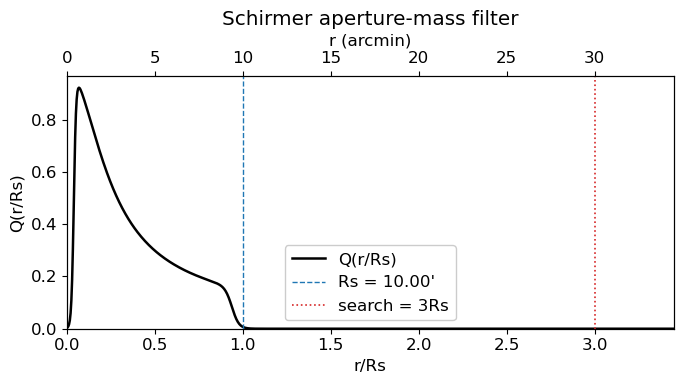

In [6]:
# Filter profile vs r/Rs, with Rs and the aperture search radius marked.
rs_arcmin = float(CONFIG["RS_ARCMIN"])
x_max = float(CONFIG["SEARCH_RADIUS_RS_MULT"]) * 1.15
x = np.linspace(1e-4, x_max, 800)
q = schirmer_weight(x * CONFIG["RS_DEG"], CONFIG["RS_DEG"])

fig_q, ax_q = plt.subplots(figsize=(7.0, 4.0))
ax_q.plot(x, q, "k-", lw=1.8, label=r"Q(r/Rs)")
ax_q.axvline(1.0, color="C0", ls="--", lw=1.0, label=fr"Rs = {rs_arcmin:.2f}'")
ax_q.axvline(
    CONFIG["SEARCH_RADIUS_RS_MULT"],
    color="C3",
    ls=":",
    lw=1.2,
    label=fr"search = {CONFIG['SEARCH_RADIUS_RS_MULT']}Rs",
)
ax_q.set_xlabel(r"r/Rs")
ax_q.set_ylabel(r"Q(r/Rs)")
ax_q.set_xlim(0, x_max)
ax_q.set_ylim(bottom=0)
ax_q.legend(framealpha=1)
ax_q.set_title("Schirmer aperture-mass filter")

ax_r = ax_q.twiny()
ax_r.set_xlim(0, x_max * rs_arcmin)
ax_r.set_xlabel(r"r (arcmin)")
fig_q.tight_layout()
save_plot(fig_q, "schirmer_filter")

In [7]:
def aperture_mass_and_sn_at_center(
    ra_c,
    dec_c,
    ra_all,
    dec_all,
    g1_all,
    g2_all,
    *,
    theta_max_arcmin,
    rs_deg,
    randomize=False,
    w_all=None,
):
    """Filtered aperture E- and B-mode statistics and S/N at one center; optional w_all weights galaxies.

    Returns (ap_e, sn_e, ap_b, sn_b) using Schirmer Q with tangential gt (E-type) and cross gx (B-type).
    """
    theta_max_deg = float(theta_max_arcmin) / 60.0
    dra = ra_all - ra_c
    ddec = dec_all - dec_c

    # Same tangent-plane metric as gamma_tx_sky (dx = dra * cos dec0) so Q(r) matches angular r.
    cos_dec0 = np.cos(np.deg2rad(dec_c))
    dtheta = np.hypot(dra * cos_dec0, ddec)

    # Restrict to sources inside the aperture; the KD-tree pre-selection is a superset of this.
    m = dtheta <= theta_max_deg
    if not np.any(m):
        return np.nan, np.nan, np.nan, np.nan

    ra_s = ra_all[m]
    dec_s = dec_all[m]
    g1_s = g1_all[m]
    g2_s = g2_all[m]
    d_theta = dtheta[m]
    n_g = int(ra_s.size)

    # Uniform weights unless per-object inverse variances are supplied.
    if w_all is None:
        w_s = np.ones(n_g, dtype=np.float64)
    else:
        w_s = np.asarray(w_all, dtype=np.float64)[m]

    gt, gx = gamma_tx_sky(ra_s, dec_s, g1_s, g2_s, center=(ra_c, dec_c))

    # Null test: scramble the tangential component to destroy any real signal.
    if randomize:
        rng = np.random.default_rng()
        ang = rng.uniform(0.0, 2.0 * np.pi)
        gt = gt * (-np.cos(ang))

    Qi = schirmer_weight(d_theta, rs_deg)
    w_sum = float(np.sum(w_s))
    if w_sum <= 0.0 or not np.isfinite(w_sum):
        return np.nan, np.nan, np.nan, np.nan

    # Weighted aperture statistics: E-mode from g_t, B-mode from g_x.
    ap_e = np.sum(Qi * gt * w_s) / w_sum
    ap_b = np.sum(Qi * gx * w_s) / w_sum

    # Shape-noise error estimate, sum_i Q_i^2 |e_i|^2 w_i^2, giving S/N = sqrt(2) * signal / noise.
    denom = np.sqrt(np.sum((Qi**2) * (g1_s**2 + g2_s**2) * (w_s**2)))
    if denom <= 0.0 or not np.isfinite(denom):
        return ap_e, np.nan, ap_b, np.nan
    sn_e = np.sqrt(2.0) * (w_sum * ap_e) / denom
    sn_b = np.sqrt(2.0) * (w_sum * ap_b) / denom
    return ap_e, sn_e, ap_b, sn_b

In [8]:
def find_peaks_shear_healpix(
    ipix_eval,
    ap_mass,
    counts,
    sn_ratio,
    nside,
    theta_max_arcmin,
    sn_min=None,
):
    """Strict local maxima on HEALPix neighbors; density cut counts/(πθ²)>0.5 arcmin⁻²; optional sn_min."""
    ipix_eval = np.asarray(ipix_eval, dtype=np.int64)
    ap_mass = np.asarray(ap_mass, dtype=np.float64)
    counts = np.asarray(counts, dtype=np.float64)
    sn_ratio = np.asarray(sn_ratio, dtype=np.float64)

    # Map HEALPix index -> position in the evaluated arrays, for neighbor lookups.
    idx_of = {int(ip): k for k, ip in enumerate(ipix_eval)}
    theta_max_arcmin = float(theta_max_arcmin)
    peaks_ipix = []

    for k, ip in enumerate(ipix_eval):
        ap = ap_mass[k]
        if not np.isfinite(ap):
            continue

        # Strict maximum against all evaluated HEALPix neighbors (unevaluated ones are skipped).
        nbrs = hp.get_all_neighbours(nside, int(ip), nest=False)
        is_peak = True
        for nj in nbrs:
            if nj < 0:
                continue
            j = idx_of.get(int(nj))
            if j is None:
                continue
            if ap <= ap_mass[j]:
                is_peak = False
                break
        if not is_peak:
            continue

        # Reject apertures that are too sparsely sampled to be trustworthy.
        density = counts[k] / (np.pi * (theta_max_arcmin**2))
        if density <= 0.5:
            continue

        # Optional signal-to-noise threshold.
        if sn_min is not None:
            if not (np.isfinite(sn_ratio[k]) and sn_ratio[k] >= sn_min):
                continue

        peaks_ipix.append(int(ip))

    return np.asarray(peaks_ipix, dtype=np.int64)

## 2.0 Load data

Read only the columns needed for selection and mapping. Neighboring tracts that overlap a
THETA_MAX buffer around the target tract are identified here and loaded after the cuts.

In [10]:
object_columns = resolve_object_columns(butler, CONFIG["TRACT"])
available_tracts = object_tract_ids(butler)
theta_max_deg = CONFIG["THETA_MAX_ARCMIN"] / 60.0
skymap = butler.get("skyMap", dataId={"skymap": CONFIG["SKYMAP"]})
NEIGHBOR_TRACTS, TRACT_BUFFER_CIRCLE = [], None
try:
    NEIGHBOR_TRACTS, TRACT_BUFFER_CIRCLE = neighbor_tract_ids(
        skymap, CONFIG["TRACT"], available_tracts, theta_max_deg
    )
except Exception as exc:
    print("Neighbor lookup failed, mapping the target tract only:", exc)

data = load_object_table(butler, CONFIG["TRACT"], object_columns)
print(f"Target tract {CONFIG['TRACT']}: {len(data):,} rows")
print("Neighbor tracts:", NEIGHBOR_TRACTS or "none")

ArrowSchema unavailable, requesting OBJECT_COLUMNS directly: The new storage class (ArrowSchema) is not compatible with the existing storage class (ArrowAstropy).
Target tract 9813: 865,287 rows
Neighbor tracts: none


## 3.0 Source selection

The cuts follow selection_cuts.md, which is written for the metadetect catalog
(object_shear_all). This notebook uses the object table and HSM regauss shapes, so each cut
is applied through its object-table counterpart:

| selection_cuts.md (metadetect) | Used here (object table) |
| --- | --- |
| all *_flags false | i-band measurement, PSF, shape, GAaP, and Sersic flags |
| bmask_flags, image_flags, mfrac < 0.1 | i-band pixelFlags_* (bad, nodata, edge, saturatedCenter, crCenter, interpolatedCenter, suspectCenter) |
| is_primary | detect_isDeblendedModelSource |
| SNR > 10 | griz Sersic flux S/N > SNR_MIN (set in CONFIG) |
| reso_factor > 0.5 | 1 - T_PSF/T_obj from the i-band second moments, > RESO_FACTOR_MIN (set in CONFIG) |
| \|g-r\|, \|r-i\|, \|i-z\| < 5 | same, on AB magnitudes from the Sersic fluxes |
| gauss_T < 20 | optional cut on i_ixx + i_iyy, disabled by default |

There is no per-object masked-pixel fraction in the object table, so mfrac is covered only
indirectly by the pixel flags. Two cuts specific to this analysis are added on top: a bound on
the HSM distortion, and the red-sequence veto in section 3.3.

### 3.1 Per-object quantities

AB magnitudes, colors, band significances, and the resolution factor for the whole table,
computed once for the diagnostics below. The cuts themselves are applied by selection_mask.

In [11]:
# Sersic fluxes and their errors, in nJy.
g_flux, g_err = _col(data, "g_sersicFlux"), _col(data, "g_sersicFluxErr")
r_flux, r_err = _col(data, "r_sersicFlux"), _col(data, "r_sersicFluxErr")
i_flux, i_err = _col(data, "i_sersicFlux"), _col(data, "i_sersicFluxErr")
z_flux, z_err = _col(data, "z_sersicFlux"), _col(data, "z_sersicFluxErr")

# AB magnitudes; non-positive fluxes become NaN and are dropped by the color cuts below.
g_mag = flux_to_abmag(g_flux)
r_mag = flux_to_abmag(r_flux)
i_mag = flux_to_abmag(i_flux)
z_mag = flux_to_abmag(z_flux)

# Adjacent-band colors for the sanity cuts, plus (g-i, r-z) for the red-sequence line.
gr = g_mag - r_mag
ri = r_mag - i_mag
iz = i_mag - z_mag
gi = g_mag - i_mag
rz = r_mag - z_mag

# Per-band detection significance.
g_snr = g_flux / g_err
r_snr = r_flux / r_err
i_snr = i_flux / i_err
z_snr = z_flux / z_err

# Resolution factor: 1 - (PSF second moments) / (object second moments).
# Values near 0 are PSF-like, so stars sit near the bottom of the diagnostic below.
reso_factor = 1 - (_col(data, "i_ixxPSF") + _col(data, "i_iyyPSF")) / (
    _col(data, "i_ixx") + _col(data, "i_iyy")
)

### 3.2 Diagnostics

Color-magnitude and resolution-against-significance planes for the full table, with the
thresholds that section 3.3 applies drawn on top.

(-1.0, 3.0)

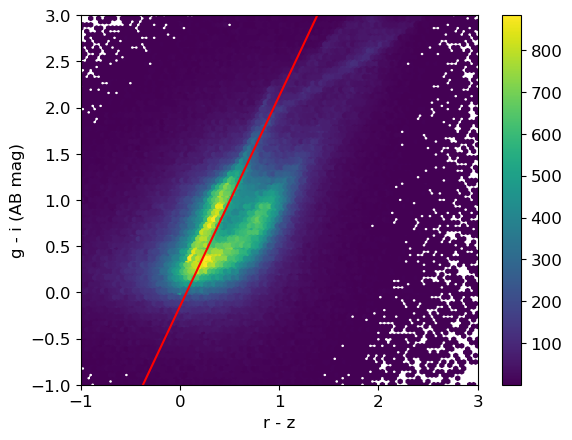

In [12]:
# Color-color plane before any cuts, with the red-sequence veto line from CONFIG.

def cc_seq_parallel(rz):
    return CONFIG["RED_SEQ_SLOPE"] * rz + CONFIG["RED_SEQ_INTERCEPT"]

plt.hexbin(rz, gi, mincnt=1, extent=(-1,3,-1,3))
s = np.linspace(-5,5, 1000)
plt.plot(s, cc_seq_parallel(s), "r-")
plt.ylabel("g - i (AB mag)")
plt.xlabel("r - z")
plt.colorbar()
plt.xlim(-1,3)
plt.ylim(-1,3)

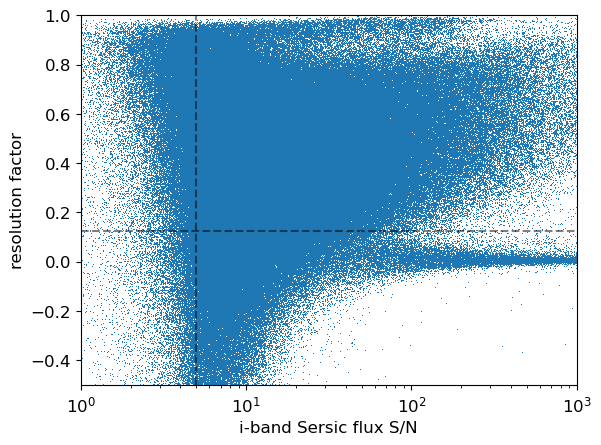

In [13]:
# Star-galaxy separation plane; the dashed lines mark the cuts applied in 3.3.
plt.plot(i_snr, reso_factor, ',')
plt.axhline(CONFIG["RESO_FACTOR_MIN"], ls='--', color='k', alpha=0.5)
plt.axvline(CONFIG["SNR_MIN"], ls='--', color='k', alpha=0.5)
plt.xlabel("i-band Sersic flux S/N")
plt.ylabel("resolution factor")
plt.ylim(-0.5, 1.0)
plt.xlim(1, 1000)
plt.semilogx()
save_plot(plt.gcf(), f"{CONFIG['TRACT']}_star_galaxy")

### 3.3 Apply the cuts

Each group is built separately so the per-cut counts show which one dominates the loss. The
red-sequence veto removes galaxies above a line of slope 2.276 in the (r−z,g−i) plane:
those are likely cluster members rather than lensed background sources, so they would dilute
the signal. After the cuts, the occupied HEALPix cells are counted so the source density on the
map grid is visible before the aperture statistic is run.

In [15]:
mask, groups = selection_mask(data)
shear_catalog = data[mask]
from_target = np.ones(len(shear_catalog), dtype=bool)

for _name, _cut in groups.items():
    print(f"{_name:<28} {int(np.sum(_cut)):>10,}")
print(f"{'all cuts':<28} {len(shear_catalog):>10,} of {len(data):,}")

measurement + pixel flags       541,165
deblended model source          745,237
|e| <= 2                        565,481
reso_factor > 0.125             590,369
extendedness + S/N > 5          401,948
colors + red sequence           439,856
size                            865,287
all cuts                        184,656 of 865,287


In [ ]:
# Source density over the tract's unique (inner) area.
tract_area = tract_area_deg2(skymap, CONFIG["TRACT"])
print(f"tract area: {tract_area:.3f} deg^2")
print(round(len(shear_catalog) / (tract_area * 3600.0), 3), "gal / arcmin^2")

(-1.0, 3.0)

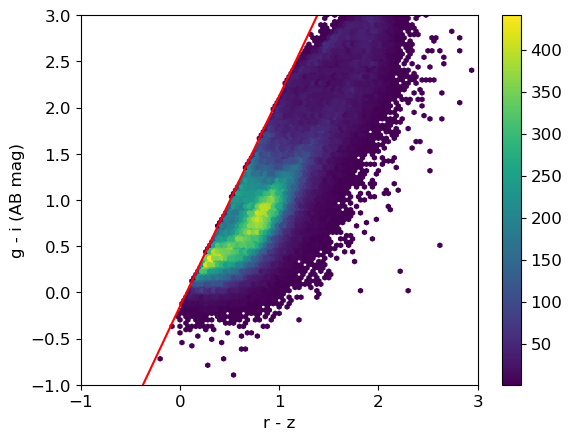

In [17]:
# Same color-color plane after the cuts: the red sequence should be removed.
plt.hexbin(
    flux_to_abmag(shear_catalog["r_sersicFlux"]) - flux_to_abmag(shear_catalog["z_sersicFlux"]), 
    flux_to_abmag(shear_catalog["g_sersicFlux"]) - flux_to_abmag(shear_catalog["i_sersicFlux"]), mincnt=1, extent=(-1,3,-1,3))
s = np.linspace(-5,5, 1000)
plt.plot(s, cc_seq_parallel(s), "r-")
plt.ylabel("g - i (AB mag)")
plt.xlabel("r - z")
plt.colorbar()
plt.xlim(-1,3)
plt.ylim(-1,3)

Number of selected galaxies in each occupied HEALPix cell (target tract, after the cuts above). This is the occupancy of the map grid, not the count inside the Schirmer search disc.

Occupied cells: 10,998  |  galaxies/cell: min=1  median=17  mean=16.8  max=48


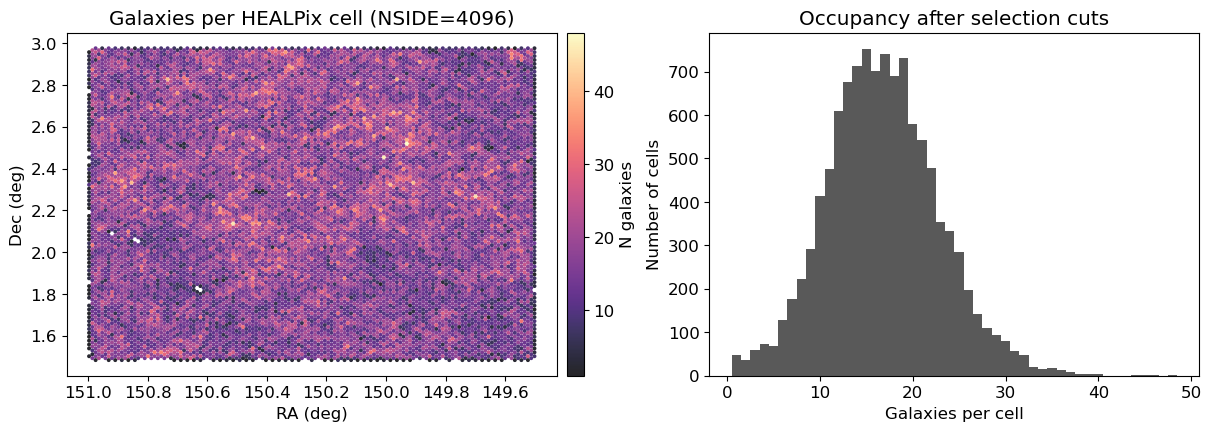

In [18]:
# Occupied HEALPix cells after the selection cuts (target tract only).
nside_gal = int(CONFIG["NSIDE"])
ra_sel = _col(shear_catalog, "coord_ra")
dec_sel = _col(shear_catalog, "coord_dec")
ipix_sel = hp.ang2pix(nside_gal, ra_sel, dec_sel, nest=False, lonlat=True)
ipix_occ, n_gal_cell = np.unique(ipix_sel, return_counts=True)
ra_cell, dec_cell = hp.pix2ang(nside_gal, ipix_occ, nest=False, lonlat=True)

print(
    f"Occupied cells: {ipix_occ.size:,}  |  "
    f"galaxies/cell: min={int(n_gal_cell.min())}  "
    f"median={np.median(n_gal_cell):.0f}  "
    f"mean={n_gal_cell.mean():.1f}  "
    f"max={int(n_gal_cell.max())}"
)

fig_ngal, axes_ngal = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
pt_ngal = max(1.0, min(8.0, 500_000.0 / max(int(ipix_occ.size), 1)))
sc_ngal = axes_ngal[0].scatter(
    ra_cell,
    dec_cell,
    c=n_gal_cell,
    s=pt_ngal,
    cmap="magma",
    linewidths=0,
    alpha=0.85,
)
axes_ngal[0].set_xlabel("RA (deg)")
axes_ngal[0].set_ylabel("Dec (deg)")
axes_ngal[0].set_title(f"Galaxies per HEALPix cell (NSIDE={nside_gal})")
axes_ngal[0].invert_xaxis()
fig_ngal.colorbar(sc_ngal, ax=axes_ngal[0], fraction=0.046, pad=0.02, label="N galaxies")

n_max = int(n_gal_cell.max())
bins_ngal = np.arange(0.5, n_max + 1.5, 1) if n_max < 80 else 40
axes_ngal[1].hist(n_gal_cell, bins=bins_ngal, histtype="stepfilled", color="0.35")
axes_ngal[1].set_xlabel("Galaxies per cell")
axes_ngal[1].set_ylabel("Number of cells")
axes_ngal[1].set_title("Occupancy after selection cuts")
save_plot(fig_ngal, f"{CONFIG['TRACT']}_ngal_cells")

### 3.4 Neighbor-tract buffer

Load selected galaxies from neighboring tracts that fall inside the THETA_MAX buffer. The mass
map is still evaluated only on the target tract. Missing neighbors are skipped.

In [19]:
n_target = len(shear_catalog)
pieces = [shear_subset(shear_catalog)]
del shear_catalog, data
gc.collect()

for tid in NEIGHBOR_TRACTS:
    try:
        tbl = load_object_table(butler, tid, object_columns)
    except Exception as exc:
        print(f"tract {tid}: skipped ({exc})")
        continue
    nb_mask, _ = selection_mask(tbl)
    sel = shear_subset(tbl[nb_mask])
    del tbl
    if len(sel) == 0:
        gc.collect()
        continue
    keep = in_circle(sel["coord_ra"], sel["coord_dec"], TRACT_BUFFER_CIRCLE)
    n_keep = int(np.sum(keep))
    if n_keep:
        pieces.append(sel[keep])
    del sel
    gc.collect()
    print(f"tract {tid}: {n_keep:,} galaxies in buffer")

shear_catalog = vstack(pieces, join_type="inner") if len(pieces) > 1 else pieces[0]
del pieces
gc.collect()

shear_catalog, from_target = dedupe_objectid(shear_catalog, n_target)
print(
    f"Shear catalog: {int(from_target.sum()):,} in tract, "
    f"{int((~from_target).sum()):,} from neighbors "
    f"({len(shear_catalog):,} unique)"
)

Shear catalog: 184,656 in tract, 0 from neighbors (184,656 unique)


## 4.0 Map on HEALPix

Every HEALPix pixel holding at least one selected galaxy in the target tract is evaluated at its
center. For each center the KD-tree gathers galaxies (including the neighbor buffer) inside the
search radius, and the Schirmer weight is applied to tangential shear gt (E-mode,
ap_mass_map / sn_ratio_map) and to cross shear g× (B-mode, ap_bmode_map / sn_bmode_map).

### 4.1 Shear calibration and weights

Regauss distortions are converted to shear with the responsivity R and multiplicative bias
m calibrated on Abell 360: $g = e / [2R(1+m)]$. Weights are the inverse of the total shape
variance, i.e. intrinsic shape noise added in quadrature with the measurement error.

In [20]:
# Quick check that the mean ellipticity is small; a large value signals additive bias.
np.mean(shear_catalog['i_hsmShapeRegauss_e1'])

np.float64(0.005566796544994476)

In [21]:
# Responsivity and multiplicative bias from the A360 calibration.
R, m_mean = 0.8511839657185559, -0.13584282915829576

ra_deg = _col(shear_catalog, "coord_ra")
dec_deg = _col(shear_catalog, "coord_dec")

# Distortion -> shear: g = e / (2R) / (1 + m).
e1_0 = _col(shear_catalog, "i_hsmShapeRegauss_e1")
e2_0 = _col(shear_catalog, "i_hsmShapeRegauss_e2")
g1 = (e1_0 / (2.0 * R)) / (1.0 + m_mean)
g2 = (e2_0 / (2.0 * R)) / (1.0 + m_mean)

# Weights: 1 / (shape noise^2 + measurement variance), with 0.26 the assumed intrinsic dispersion.
_var_sum = (0.26**2 + _col(shear_catalog, 'i_hsmShapeRegauss_sigma'))
with np.errstate(divide="ignore", invalid="ignore"):
    w_gal = np.where(np.isfinite(_var_sum) & (_var_sum > 0.0), 1.0 / _var_sum, 0.0)

print("N galaxies:", ra_deg.size)
print("Galaxies with positive finite weight:", int(np.sum(w_gal > 0)))

N galaxies: 184656
Galaxies with positive finite weight: 184656


### 4.2 Aperture statistic on every cell

The loop is over unique occupied pixels in the target tract, so runtime scales with the covered
area rather than with the full sphere. Neighbor-tract galaxies enter only through the KD-tree.

In [23]:
theta_max_arcmin = CONFIG["THETA_MAX_ARCMIN"]
rs_deg = float(CONFIG["RS_DEG"])
nside = int(CONFIG["NSIDE"])
theta_max_deg = theta_max_arcmin / 60.0

# Evaluate only pixels that contain a target-tract galaxy; the tree includes the buffer.
ipix_gal = hp.ang2pix(nside, ra_deg, dec_deg, nest=False, lonlat=True)
ipix_eval = np.unique(ipix_gal[from_target])

# KD-tree in flat (RA, Dec); the exact angular cut is redone inside the aperture function.
xy = np.column_stack([ra_deg, dec_deg])
tree = cKDTree(xy)

# Output maps, indexed like ipix_eval rather than by HEALPix index.
n_cell = int(ipix_eval.size)
ap_mass_map = np.full(n_cell, np.nan, dtype=np.float64)
sn_ratio_map = np.full(n_cell, np.nan, dtype=np.float64)
ap_bmode_map = np.full(n_cell, np.nan, dtype=np.float64)
sn_bmode_map = np.full(n_cell, np.nan, dtype=np.float64)
counts_map = np.zeros(n_cell, dtype=np.int32)

for k, ip in enumerate(tqdm(ipix_eval, desc="HEALPix cells")):
    # Cell center, then all galaxies within the search radius of it.
    ra_c, dec_c = hp.pix2ang(nside, int(ip), nest=False, lonlat=True)
    idx = tree.query_ball_point([float(ra_c), float(dec_c)], r=theta_max_deg)
    if not idx:
        continue

    idx = np.asarray(idx, dtype=np.int64)
    ra_s = ra_deg[idx]
    dec_s = dec_deg[idx]
    g1_s = g1[idx]
    g2_s = g2[idx]
    counts_map[k] = int(ra_s.size)

    ap_mass_map[k], sn_ratio_map[k], ap_bmode_map[k], sn_bmode_map[k] = aperture_mass_and_sn_at_center(
        float(ra_c),
        float(dec_c),
        ra_s,
        dec_s,
        g1_s,
        g2_s,
        theta_max_arcmin=theta_max_arcmin,
        rs_deg=rs_deg,
        randomize=False,
        w_all=w_gal[idx],
    )

print("N HEALPix cells evaluated:", n_cell)
print("Finite E-mode (aperture mass) cells:", int(np.isfinite(ap_mass_map).sum()))
print("Finite B-mode cells:", int(np.isfinite(ap_bmode_map).sum()))

HEALPix cells:   0%|          | 0/10998 [00:00<?, ?it/s]

N HEALPix cells evaluated: 10998
Finite E-mode (aperture mass) cells: 10998
Finite B-mode cells: 10998


### 4.3 Save the map

Writes the evaluated cell centers and their E/B aperture values to output/.

In [24]:
# Sky coordinates of the evaluated cell centers.
ra_pix, dec_pix = hp.pix2ang(nside, ipix_eval, nest=False, lonlat=True)
ra_pix = np.asarray(ra_pix, dtype=np.float64)
dec_pix = np.asarray(dec_pix, dtype=np.float64)

In [25]:
aper = Table(data=[ra_pix, dec_pix, ap_mass_map, ap_bmode_map], names=["RA", "DEC", "E_ap", "B_ap"])
aper.write(OUTPUT_DIR / f"{CONFIG['TRACT']}_shapeHSM_massmap.fits", format="fits", overwrite=True)

## 5.0 Peaks

Local maxima on the HEALPix neighbor graph, with the same surface-density cut as above and an
optional S/N threshold from config.

In [26]:
sn_min = CONFIG.get("PEAK_SN_MIN")
peak_ipix = find_peaks_shear_healpix(
    ipix_eval,
    ap_mass_map,
    counts_map,
    sn_ratio_map,
    nside,
    theta_max_arcmin=theta_max_arcmin,
    sn_min=sn_min,
)
print("N peaks (with current cuts):", int(peak_ipix.size))

N peaks (with current cuts): 12


## 6.0 Figures

RA/Dec scatter maps, S/N with peaks, and gnomonic healpy views when NSIDE is small enough to
hold the full-sky map in memory.

### 6.1 Plot setup

Color limits from the 5th-95th percentiles, a point size that scales with the number of cells,
and the dense full-sky arrays needed by hp.gnomview.

In [27]:
# Recompute the cell centers so the figures can be run without the save step.
ra_pix, dec_pix = hp.pix2ang(nside, ipix_eval, nest=False, lonlat=True)
ra_pix = np.asarray(ra_pix, dtype=np.float64)
dec_pix = np.asarray(dec_pix, dtype=np.float64)

# Only plot cells with at least one galaxy in the aperture.
msk = counts_map > 0
if msk.any():
    m_lo, m_hi = np.nanpercentile(ap_mass_map[msk], [5, 95])
    sn_lo, sn_hi = np.nanpercentile(sn_ratio_map[msk], [5, 95])
    b_lo, b_hi = np.nanpercentile(ap_bmode_map[msk], [5, 95])
    snb_lo, snb_hi = np.nanpercentile(sn_bmode_map[msk], [5, 95])
else:
    m_lo = m_hi = sn_lo = sn_hi = b_lo = b_hi = snb_lo = snb_hi = None

# Marker size shrinks as the number of plotted cells grows.
pt_size = max(1.0, min(8.0, 500_000.0 / max(int(ipix_eval.size), 1)))

# gnomview needs a full-sky array, so skip it if that would be too large.
MAX_DENSE_NPIX = 4_000_000
_npix_hp = hp.nside2npix(nside)
do_gnomonic = _npix_hp <= MAX_DENSE_NPIX
if do_gnomonic:
    # Center the projection on the data.
    rot_ra = float(np.median(ra_pix))
    rot_dec = float(np.median(dec_pix))

    # Scatter the E-mode S/N onto the full sky, marking empty pixels as UNSEEN.
    sn_dense = np.full(_npix_hp, np.nan, dtype=np.float64)
    sn_dense[ipix_eval] = sn_ratio_map
    hp_sm = np.copy(sn_dense)
    hp_sm[~np.isfinite(hp_sm)] = hp.UNSEEN

    # Same for the B-mode S/N.
    snb_dense = np.full(_npix_hp, np.nan, dtype=np.float64)
    snb_dense[ipix_eval] = sn_bmode_map
    hp_smb = np.copy(snb_dense)
    hp_smb[~np.isfinite(hp_smb)] = hp.UNSEEN
else:
    hp_sm = hp_smb = None

### 6.2 E-mode maps

Aperture mass, its S/N, and the number of galaxies per aperture, which shows where the maps are
noise-dominated.

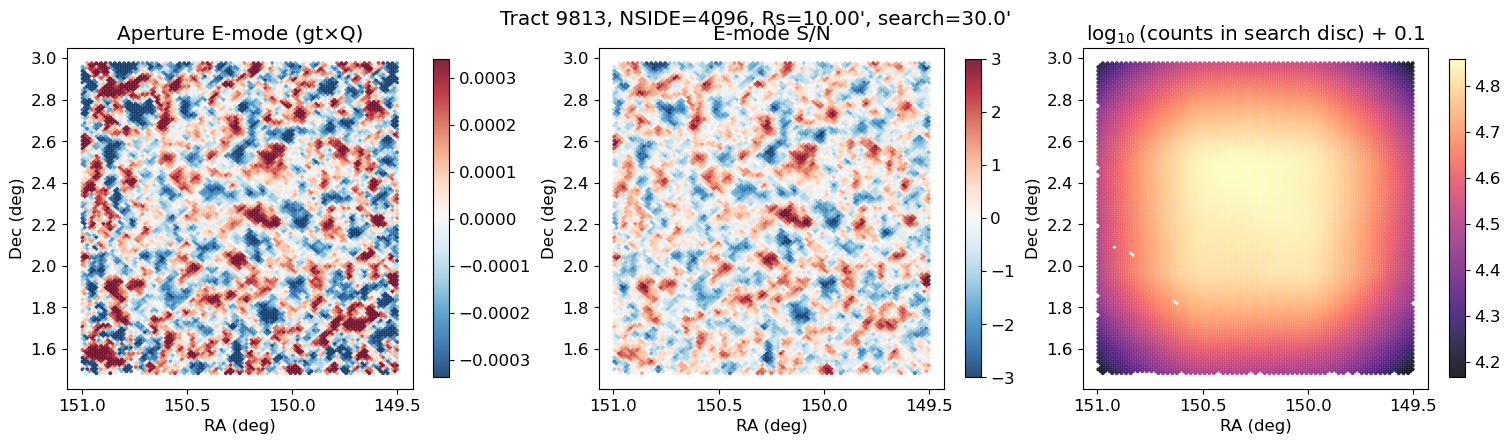

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)

# Left: aperture E-mode signal.
sc0 = axes[0].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=ap_mass_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=m_lo,
    vmax=m_hi,
    linewidths=0,
    alpha=0.85,
)
axes[0].set_xlabel("RA (deg)")
axes[0].set_ylabel("Dec (deg)")
axes[0].set_title(r"Aperture E-mode (gt×Q)")
axes[0].invert_xaxis()  # RA increases to the left
fig.colorbar(sc0, ax=axes[0], fraction=0.046, pad=0.02)

# Middle: the same quantity divided by its shape-noise error.
sc1 = axes[1].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=sn_ratio_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=-3.0,
    vmax=3.0,
    linewidths=0,
    alpha=0.85,
)
axes[1].set_xlabel("RA (deg)")
axes[1].set_ylabel("Dec (deg)")
axes[1].set_title(r"E-mode S/N")
axes[1].invert_xaxis()
fig.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.02)

# Right: source density per aperture, offset before the log to keep empty cells finite.
logc = np.log10(counts_map.astype(np.float64) + 0.1)
sc2 = axes[2].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=logc[msk],
    s=pt_size,
    cmap="magma",
    linewidths=0,
    alpha=0.85,
)
axes[2].set_xlabel("RA (deg)")
axes[2].set_ylabel("Dec (deg)")
axes[2].set_title(r"$\log_{10}$(counts in search disc) + 0.1")
axes[2].invert_xaxis()
fig.colorbar(sc2, ax=axes[2], fraction=0.046, pad=0.02)

fig.suptitle(
    f"Tract {CONFIG['TRACT']}, NSIDE={nside}, Rs={CONFIG['RS_ARCMIN']:.2f}', search={theta_max_arcmin:.1f}'",
    y=1.02,
)
save_plot(fig, f"{CONFIG['TRACT']}_E-mode_map")

### 6.3 B-mode maps

Same filter and weights applied to the cross shear. Structure here at the level of the E-mode
maps would indicate systematics rather than lensing.

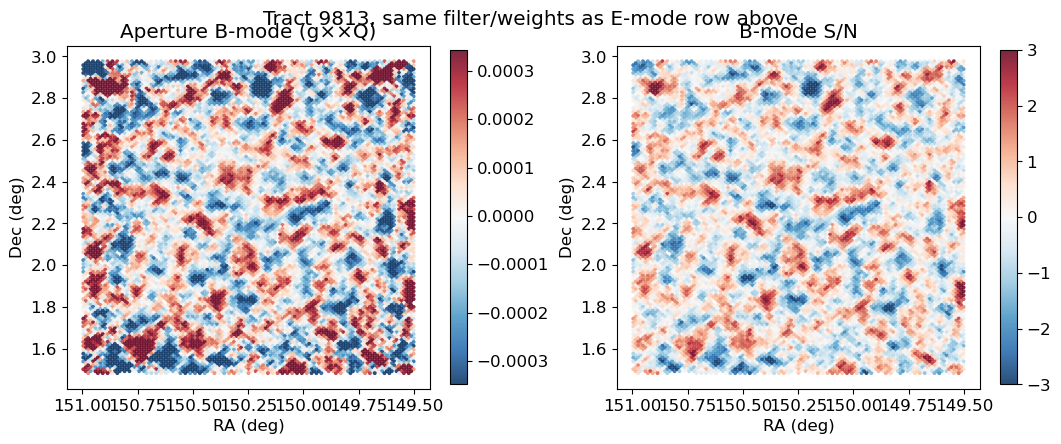

In [29]:
fig_eb, axes_eb = plt.subplots(1, 2, figsize=(10.5, 4.2), constrained_layout=True)

# Left: aperture B-mode signal.
scb0 = axes_eb[0].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=ap_bmode_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=b_lo,
    vmax=b_hi,
    linewidths=0,
    alpha=0.85,
)
axes_eb[0].set_xlabel("RA (deg)")
axes_eb[0].set_ylabel("Dec (deg)")
axes_eb[0].set_title(r"Aperture B-mode (g××Q)")
axes_eb[0].invert_xaxis()
fig_eb.colorbar(scb0, ax=axes_eb[0], fraction=0.046, pad=0.02)

# Right: B-mode S/N.
scb1 = axes_eb[1].scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=sn_bmode_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=-3.0,
    vmax=3.0,
    linewidths=0,
    alpha=0.85,
)
axes_eb[1].set_xlabel("RA (deg)")
axes_eb[1].set_ylabel("Dec (deg)")
axes_eb[1].set_title(r"B-mode S/N")
axes_eb[1].invert_xaxis()
fig_eb.colorbar(scb1, ax=axes_eb[1], fraction=0.046, pad=0.02)

fig_eb.suptitle(
    f"Tract {CONFIG['TRACT']}, same filter/weights as E-mode row above",
    y=1.02,
)
save_plot(fig_eb, f"{CONFIG['TRACT']}_B-mode_map")

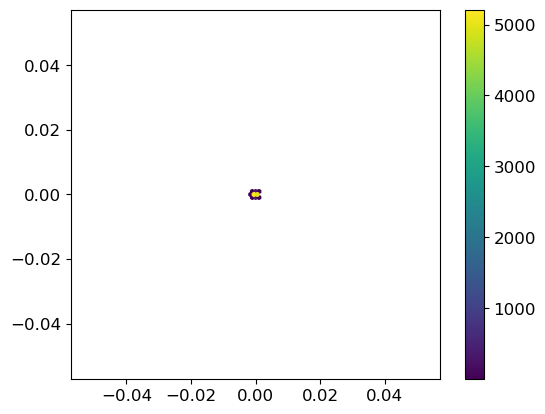

In [30]:
# E-mode against B-mode aperture values per occupied cell.
plt.hexbin(ap_mass_map[msk], ap_bmode_map[msk], mincnt=1)
plt.colorbar()
plt.gca().set_aspect(1)
save_plot(plt.gcf(), f"{CONFIG['TRACT']}_EB_hexbin")

In [ ]:
# Histogram of E-mode and B-mode aperture values per occupied cell.
# B should look like pure noise; an E-mode tail beyond it is the lensing signal.
e_vals = ap_mass_map[msk]
b_vals = ap_bmode_map[msk]
e_vals = e_vals[np.isfinite(e_vals)]
b_vals = b_vals[np.isfinite(b_vals)]
eb_bins = np.histogram_bin_edges(np.concatenate([e_vals, b_vals]), bins=60)

fig_hist, ax_hist = plt.subplots(figsize=(6, 4.2), constrained_layout=True)
ax_hist.hist(e_vals, bins=eb_bins, histtype="step", linewidth=1.5, label="E-mode")
ax_hist.hist(b_vals, bins=eb_bins, histtype="step", linewidth=1.5, label="B-mode")
ax_hist.set_xlabel("Aperture mass")
ax_hist.set_ylabel("Number of cells")
ax_hist.legend()
save_plot(fig_hist, f"{CONFIG['TRACT']}_EB_hist")

### 6.4 Peaks against known clusters

Detected peaks are circled, and four catalogued groups or clusters in the field are marked for
comparison.

[150.56762695 149.95239258 150.27099609 150.98510742 149.62280273
 150.17211914 150.15014648 150.08422852 150.26000977 149.51293945
 150.85327148 149.98535156] [2.87345374 2.72406775 2.67738847 2.59337024 2.38801546 2.2573513
 2.22002086 2.201356   2.03338253 1.92141001 1.90274865 1.50157496]


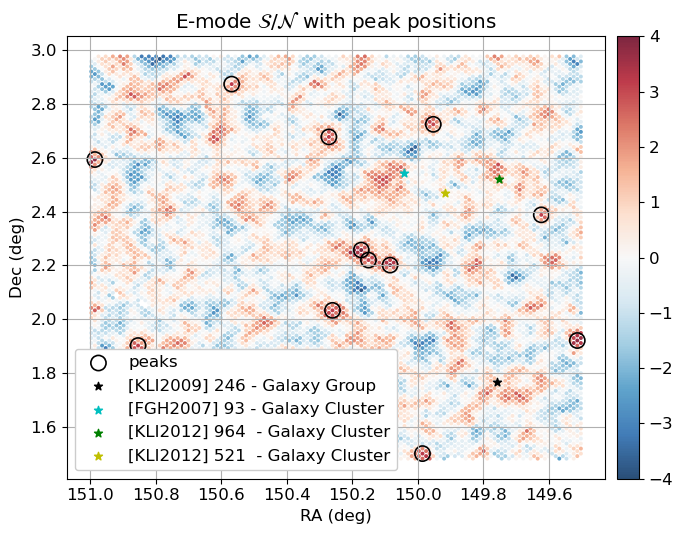

In [31]:
fig2, axp = plt.subplots(figsize=(7, 5.5))

# E-mode S/N on a fixed -4 to 4 scale so peak significance is directly readable.
sc = axp.scatter(
    ra_pix[msk],
    dec_pix[msk],
    c=sn_ratio_map[msk],
    s=pt_size,
    cmap="RdBu_r",
    vmin=-4,
    vmax=4,
    linewidths=0,
    alpha=0.85,
)

# Circle the detected peaks.
if peak_ipix.size:
    ra_peak, dec_peak = hp.pix2ang(nside, peak_ipix, nest=False, lonlat=True)
    axp.scatter(
        ra_peak,
        dec_peak,
        s=120,
        facecolors="none",
        edgecolors="k",
        linewidths=1.2,
        label="peaks",
    )
    print(ra_peak, dec_peak)

axp.set_xlabel("RA (deg)")
axp.set_ylabel("Dec (deg)")

# Known groups and clusters in this field, for cross-checking the peaks.
axp.scatter(149.7575000, 1.7666667, marker='*', color='k', label='[KLI2009] 246 - Galaxy Group')
axp.scatter(150.0430000, 2.5450000, marker='*', color='c', label='[FGH2007] 93 - Galaxy Cluster')
axp.scatter(149.7507083, 2.5198333, marker='*', color='g', label='[KLI2012] 964  - Galaxy Cluster')
axp.scatter(149.9167500, 2.4696389, marker='*', color='y', label='[KLI2012] 521  - Galaxy Cluster')
axp.grid()
axp.set_title(r"E-mode $\mathcal{S}/\mathcal{N}$ with peak positions")
axp.invert_xaxis()
fig2.colorbar(sc, ax=axp, fraction=0.046, pad=0.02)
axp.legend(loc="lower left", framealpha=1)
fig2.tight_layout()
save_plot(fig2, f"{CONFIG['TRACT']}_E-mode_sn_ratio")